<a href="https://colab.research.google.com/github/kylevalibia/IDX-Exchange-Data-Science/blob/main/05_advanced_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Read data from Google Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
path = "/content/drive/MyDrive/IDX Exchange Internship Fall 2026/Data/"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Mounted at /content/drive


In [2]:
# Dataset from end of Notebook 4, contains all engineered features
x_train = pd.read_csv(path + "x_train_feat.csv", low_memory=False)
x_valid = pd.read_csv(path + "x_valid_feat.csv", low_memory=False)
x_test = pd.read_csv(path + "x_test_feat.csv", low_memory=False)

y_train = pd.read_csv(path + "actual_train_vals.csv", low_memory=False)
y_valid = pd.read_csv(path + "actual_valid_vals.csv", low_memory=False)
y_test = pd.read_csv(path + "actual_test_vals.csv", low_memory=False)

results = pd.read_csv(path + "04_results.csv", low_memory=False)

# XGBoost

In [3]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def xgboost(params, x_train, y_train, x_eval, y_eval, name, plot=True):
  model = params

  model.fit(x_train, np.log(y_train))
  pred_dollars = np.exp(model.predict(x_eval))
  actual_dollars = np.asarray(y_eval).ravel()

  r2 = r2_score(actual_dollars, pred_dollars)
  rmse = np.sqrt(mean_squared_error(actual_dollars, pred_dollars))
  mae = mean_absolute_error(actual_dollars, pred_dollars)

  if plot:
    print(name)
    print(f"R2: {r2:.4f}")
    print(f"RMSE: ${rmse:,.2f}")
    print(f"MAE: ${mae:,.2f}")

    residuals = actual_dollars - pred_dollars
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].scatter(actual_dollars, pred_dollars, alpha=0.3, s=10, color="mediumseagreen")
    lims = [min(actual_dollars.min(), pred_dollars.min()),
            max(actual_dollars.max(), pred_dollars.max())]
    axes[0].plot(lims, lims, "r--", label="Perfect prediction")
    axes[0].set_xlabel("Actual ClosePrice ($)")
    axes[0].set_ylabel("Predicted ClosePrice ($)")
    axes[0].set_title("Actual vs. Predicted")
    axes[0].legend()

    axes[1].scatter(pred_dollars, residuals, alpha=0.3, s=10, color="lightcoral")
    axes[1].axhline(0, color="r", linestyle="--")
    axes[1].set_xlabel("Predicted ClosePrice ($)")
    axes[1].set_ylabel("Residual ($)")
    axes[1].set_title("Residuals vs. Predicted")

    plt.tight_layout()
    plt.show()

  return [name, r2, rmse, mae]

## Tuning Depth

In [55]:
rows = []
t_rows = []
for depth in [1, 2, 3, 4, 6, 8, 10, 0]:
  xgb = XGBRegressor(max_depth=depth, subsample=0.5, colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=0)
  result = xgboost(xgb, x_train, y_train, x_valid, y_valid, f"XGB depth={depth} lr=0.3 n=100", plot=False)
  t_result = xgboost(xgb, x_train, y_train, x_train, y_train, f"XGB depth={depth} lr=0.3 n=100", plot=False)

  rows.append(result)
  t_rows.append(t_result)

train_tuning = pd.DataFrame(t_rows, columns=["name", "R2", "RMSE", "MAE"])
depth_tuning = pd.DataFrame(rows, columns=["name", "R2", "RMSE", "MAE"])

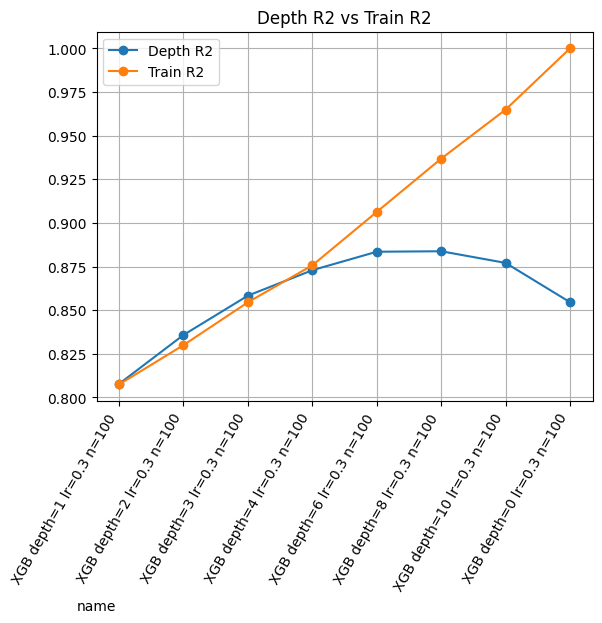

,name,Depth R2,Train R2,R2 Difference
5,XGB depth=8 lr=0.3 n=100,0.883746,0.936796,-0.053050
4,XGB depth=6 lr=0.3 n=100,0.883461,0.906264,-0.022802
6,XGB depth=10 lr=0.3 n=100,0.877068,0.964899,-0.087830
3,XGB depth=4 lr=0.3 n=100,0.872878,0.875666,-0.002788
2,XGB depth=3 lr=0.3 n=100,0.858291,0.854489,0.003802
7,XGB depth=0 lr=0.3 n=100,0.854545,0.999998,-0.145452
1,XGB depth=2 lr=0.3 n=100,0.835764,0.829939,0.005825
0,XGB depth=1 lr=0.3 n=100,0.807713,0.807393,0.000320


In [80]:
depth_results = pd.merge(depth_tuning, train_tuning, on="name").drop(columns=["RMSE_x", "MAE_x", "RMSE_y", "MAE_y"]).rename(columns={"R2_x": "Depth R2", "R2_y": "Train R2"})
depth_results["R2 Difference"] = depth_results["Depth R2"] - depth_results["Train R2"]

ax = depth_results.plot(x="name", y=["Depth R2", "Train R2"], marker="o", rot=60)
ax.xaxis.label.set_position((0, -0.1))
plt.xticks(horizontalalignment='right')

plt.title("Depth R2 vs Train R2")
plt.grid()
plt.show();

display(depth_results.sort_values(by="Depth R2", ascending=False))

## Tuning Learning Rate & n_estimators

In [83]:
rows = []
t_rows = []
for trees in [50, 80, 100, 200]:
  for rate in [0.02, 0.05, 0.1, 0.2, 0.3]:
    xgb = XGBRegressor(n_estimators=trees, learning_rate=rate, subsample=0.5, colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=0)
    result = xgboost(xgb, x_train, y_train, x_valid, y_valid, f"XGB depth=6 lr={rate} n={trees}", plot=False)
    t_result = xgboost(xgb, x_train, y_train, x_train, y_train, f"XGB depth=6 lr={rate} n={trees}", plot=False)

    rows.append(result)
    t_rows.append(t_result)

trees_lr_tuning = pd.DataFrame(rows, columns=["name", "R2", "RMSE", "MAE"])
train_tuning = pd.DataFrame(t_rows, columns=["name", "R2", "RMSE", "MAE"])

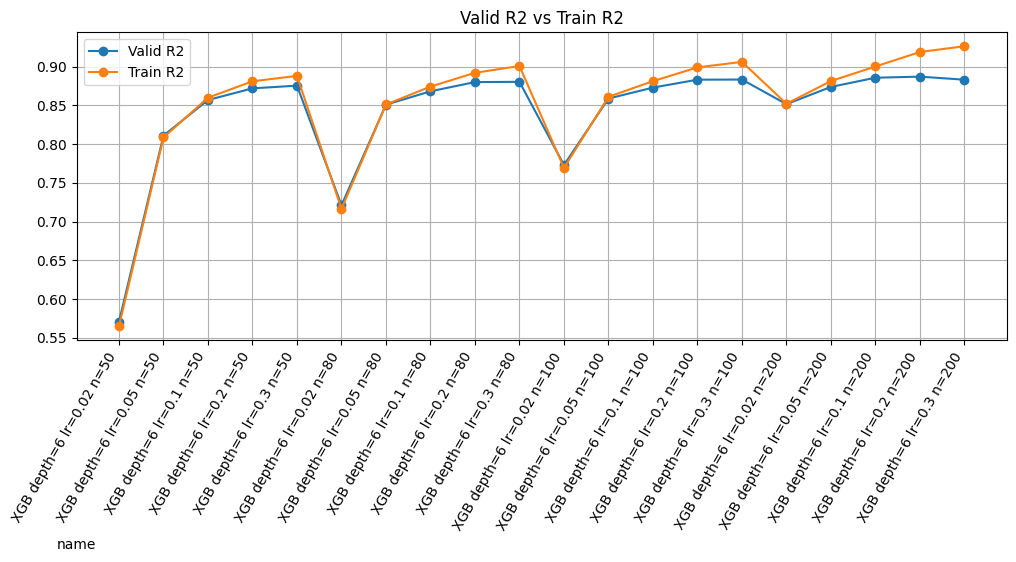

,name,Valid R2,Train R2,R2 Difference
18,XGB depth=6 lr=0.2 n=200,0.887204,0.919050,-0.031846
17,XGB depth=6 lr=0.1 n=200,0.885823,0.900327,-0.014504
14,XGB depth=6 lr=0.3 n=100,0.883461,0.906264,-0.022802
13,XGB depth=6 lr=0.2 n=100,0.883300,0.899190,-0.015890
19,XGB depth=6 lr=0.3 n=200,0.883268,0.926482,-0.043214
9,XGB depth=6 lr=0.3 n=80,0.880482,0.900949,-0.020467
8,XGB depth=6 lr=0.2 n=80,0.880195,0.892163,-0.011968
4,XGB depth=6 lr=0.3 n=50,0.875577,0.888188,-0.012611
16,XGB depth=6 lr=0.05 n=200,0.873951,0.881532,-0.007581
12,XGB depth=6 lr=0.1 n=100,0.873052,0.881407,-0.008355


In [94]:
lr_tree_results = pd.merge(trees_lr_tuning, train_tuning, on="name").drop(columns=["RMSE_x", "MAE_x", "RMSE_y", "MAE_y"]).rename(columns={"R2_x": "Valid R2", "R2_y": "Train R2"})
lr_tree_results["R2 Difference"] = lr_tree_results["Valid R2"] - lr_tree_results["Train R2"]

ax = lr_tree_results.plot(x="name", y=["Valid R2", "Train R2"], marker="o", rot=60, figsize=(12, 4))
ax.xaxis.label.set_position((0, -0.1))
plt.xticks(horizontalalignment='right')

ax.set_xticks(range(len(lr_tree_results)))
ax.set_xticklabels(lr_tree_results['name'])

plt.title("Valid R2 vs Train R2")
plt.grid()
plt.show();

display(lr_tree_results.sort_values(by="Valid R2", ascending=False).head(12))

Main take away is higher trees pair well with lower learning rates.

## Tuning the Best of the Three

Taking the highest performing of three of the depths, three of the learning rates, and two of the number of trees.

In [4]:
rows = []
t_rows = []
for depth in [6, 8]:
  for rate in [0.02, 0.05, 0.1]:
    for n_est in [400, 600, 800]:
      xgb = XGBRegressor(n_estimators=n_est, max_depth=depth, learning_rate=rate, subsample=0.5, colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=0)
      res = xgboost(xgb, x_train, y_train, x_valid, y_valid, f"XGB depth={depth} lr={rate} n={n_est}", plot=False)
      trains = xgboost(xgb, x_train, y_train, x_train, y_train, f"XGB depth={depth} lr={rate} n={n_est}", plot=False)

      rows.append(res)
      t_rows.append(trains)


tuning = pd.DataFrame(rows, columns=["name", "R2", "RMSE", "MAE"])
t_tuning = pd.DataFrame(t_rows, columns=["name", "R2", "RMSE", "MAE"])

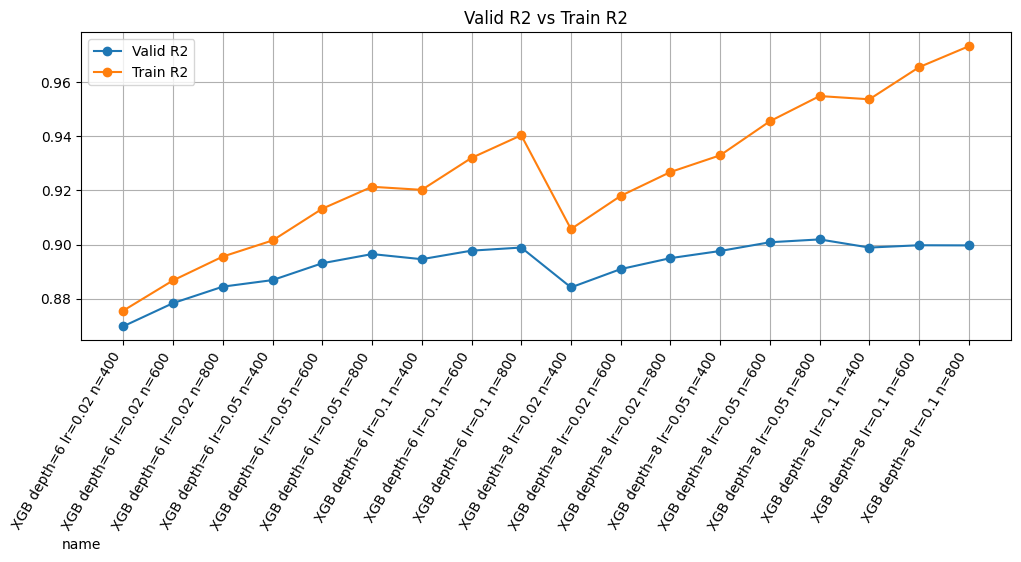

,name,Valid R2,Train R2,R2 Difference
14,XGB depth=8 lr=0.05 n=800,0.901892,0.954832,-0.052940
13,XGB depth=8 lr=0.05 n=600,0.900838,0.945530,-0.044692
16,XGB depth=8 lr=0.1 n=600,0.899734,0.965501,-0.065766
17,XGB depth=8 lr=0.1 n=800,0.899680,0.973230,-0.073550
8,XGB depth=6 lr=0.1 n=800,0.898886,0.940356,-0.041470
15,XGB depth=8 lr=0.1 n=400,0.898884,0.953640,-0.054756
7,XGB depth=6 lr=0.1 n=600,0.897740,0.931992,-0.034252
12,XGB depth=8 lr=0.05 n=400,0.897614,0.932952,-0.035338
5,XGB depth=6 lr=0.05 n=800,0.896474,0.921324,-0.024851
11,XGB depth=8 lr=0.02 n=800,0.894975,0.926778,-0.031804


In [5]:
tuning_results = pd.merge(tuning, t_tuning, on="name").drop(columns=["RMSE_x", "MAE_x", "RMSE_y", "MAE_y"]).rename(columns={"R2_x": "Valid R2", "R2_y": "Train R2"})
tuning_results["R2 Difference"] = tuning_results["Valid R2"] - tuning_results["Train R2"]

ax = tuning_results.plot(x="name", y=["Valid R2", "Train R2"], marker="o", rot=60, figsize=(12, 4))
ax.xaxis.label.set_position((0, -0.1))
plt.xticks(horizontalalignment='right')

ax.set_xticks(range(len(tuning_results)))
ax.set_xticklabels(tuning_results['name'])

plt.title("Valid R2 vs Train R2")
plt.grid()
plt.show();

display(tuning_results.sort_values(by="Valid R2", ascending=False))

Notes on tuning:

*   lr=0.05 is low across all settings, lower overfitting worries
*   lr=0.2 stagnates at a faster rate than lr=0.1, **dropped lr=0.2**
*   **lower lr pairs well with higher trees**, resulting in lower overfitting worries
*   n=50 is very comparable to n=80, kept n=80 due to higher $R^2$, **dropped n=50**
*   depth=4 is EXTREMELEY stable, training $R^2$ is consistent with validation, but scores consistently lower than depth=6. **dropped depth=4**
*   depth=10 has a high difference in $R^2$, **dropped depth=10**
*   decided depth=6 and depth=8 are the most optimal
*   more trees + higher depth results in a model that slowly starts overfitting, going to try more depths using only depth=6 with lower learning rates
*   starting at n=1000, $R^2$ score hardly increases as the diff continues to grow above 0.04 (EXCEPT at lr=0.02, 0.05), **dropping lr=0.1 as i continue increasing n**
*   n=1500,2000 becomes more expensive, and scores start to stagnate while the diff increases, lr=0.02 and n=2000 performs comparable to lr=0.05 and n=800,choose lower trees to reduce runtime. **cutoff at n=1000**
*   depth=8 starts overfitting as n increases meanwhile depth=6 remains fine, **dropped depth=8**

Possible choices:
*   Conservative choices:
1.   depth=6 lr=0.02 n=1000 ($R^2$=0.0.888207, diff=-0.013814)
1.   depth=6 lr=0.1 n=200 ($R^2$=0.885823, diff=-0.014504)
2.   depth=6 lr=0.02 n=800 ($R^2$=0.884444, diff=-0.011119)

*   Choices with diff < 0.0300
1.   depth=6 lr=0.05 n=800 ($R^2$=0.896474, diff=-0.024851) <----------
1.   depth=6 lr=0.1 n=400 ($R^2$=0.894585, diff=-0.025608)
1.   depth=8 lr=0.1 n=150 ($R^2$=0.893082, diff=-0.028698)
2.   depth=6 lr=0.05 n=600 ($R^2$=0.893092, diff=-0.020144)




In [8]:
x_train.columns

Index(['Latitude', 'Longitude', 'logLivingArea', 'logLotSizeSquareFeet',
       'BedroomsTotal', 'BathroomsTotalInteger', 'AgeAtSale', 'CityPriceLevel',
       'MonthIndex', 'LotSize_missing', 'SaleYear', 'SaleMonth',
       'LivingAreaXCityLevel', 'LotSizeXCityLevel', 'BedBathRatio', 'LatSq',
       'LonSq', 'LatXLon', 'DistrictPriceLevel'],
      dtype='object')

# Test Set

XGBoost depth=6 lr=0.05 n=800 (Test)
R2: 0.8874
RMSE: $321,173.05
MAE: $161,964.12


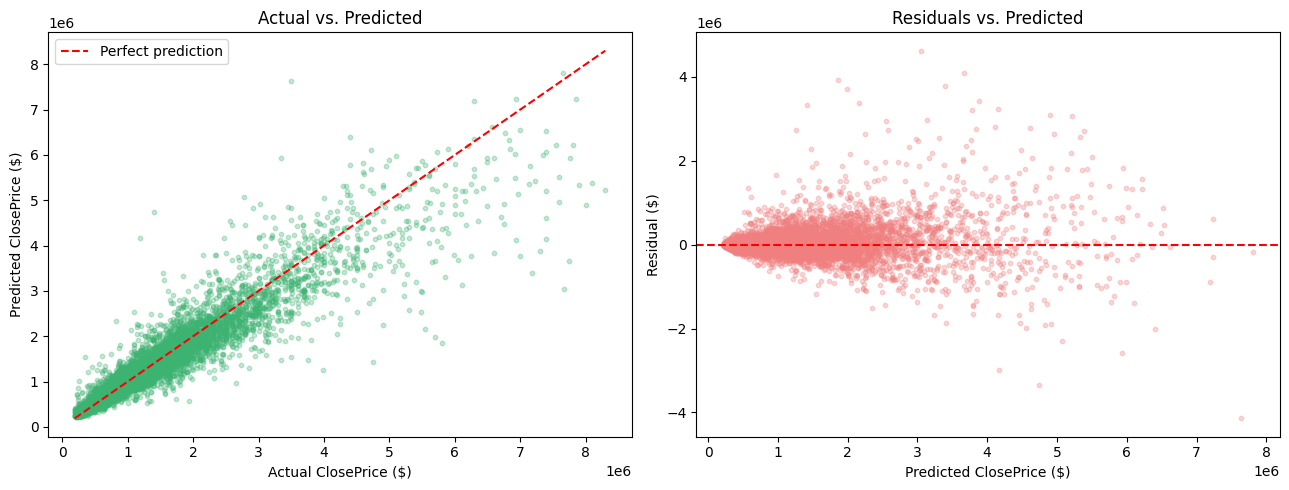

In [139]:
best_xgb = XGBRegressor(n_estimators=800, max_depth=6, learning_rate=0.05, subsample=0.5, colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=0)

final_res = xgboost(best_xgb, x_train, y_train, x_test, y_test, "XGBoost depth=6 lr=0.05 n=800 (Test)")

results.loc[len(results)] = final_res

In [140]:
display(results)

,Model,R2,RMSE,MAE
0,Linear Regression v1 (Test),0.803955,423696.580000,216334.040000
1,Linear Regression v2 w/ int. (Test),0.788188,440411.920000,230701.630000
2,"Decision Tree d=12, leaf=20 (Test)",0.822139,403575.110000,204568.640000
3,RF Depth=20 Leaf=2 (Test),0.862612,354698.059982,173894.098020
4,Linear Regression w/ Feats. (Test),0.790414,438091.290000,227364.220000
5,"DT d=12, leaf=20 w/ Feats. (Test)",0.821981,403754.570000,205603.370000
6,"RF d=20, leaf=2 w/ Feats. (Test)",0.872468,341737.842834,166830.598166
7,XGBoost depth=6 lr=0.05 n=800 (Test),0.887355,321173.052267,161964.119483
